In [1]:
# ติดตั้งแพ็กเกจเมื่อรันใน repo — บน Kaggle มี pandas/matplotlib พร้อมอยู่แล้ว
from pathlib import Path

if Path("requirements-offline.txt").exists():
    get_ipython().run_line_magic(
        "pip", "install -r requirements-offline.txt --quiet")
else:
    print("ข้ามการติดตั้ง — ใช้แพ็กเกจที่มีใน environment (เช่น Kaggle)")

/Users/utarn/projects/datascience-metrology/.venv/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Module M3 — ข้อมูลไม่สะอาด

|  |  |
|---|---|
| **เวลา** | Day 1, 14:15–15:45 (90 นาที) · Offline (CPU) |
| **ข้อมูล** | UCI Adult · Coffee Quality Database · PCD PM2.5 ปี 2556 |

**เมื่อจบโมดูลนี้ ผู้เรียนจะ...**

- ตรวจจับข้อมูลสกปรก 4 ปัญหาหลักได้: **ค่าว่าง · สะกดไม่ตรง · วันที่แปลก · ซ้ำซ้อน**
- จัดการค่าว่างด้วยการตัดสินใจที่มีเหตุผล (ตัดทิ้ง vs เติมค่า) ไม่ใช่รันคำสั่งตามโน้ต
- อ่านไฟล์ที่ไม่ใช่ UTF-8 (TIS-620) และวันที่รูปแบบแปลกได้
- ได้ตารางสะอาดที่พร้อมเป็นวัตถุดิบของกราฟ (M4) และสถิติ (M5)

**ข้อมูลที่ใช้ (citation):**

> Kohavi, R. & Becker, B. (1996). *Adult* [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20 (CC BY 4.0)
>
> LeDoux, J. (2018). *coffee-quality-database* [Data set]. GitHub, https://github.com/jldbc/coffee-quality-database (data © Coffee Quality Institute) — MIT
>
> กรมควบคุมมลพิษ (2556). *ข้อมูลคุณภาพอากาศ PM2.5 กทม.* pcd.gdcatalog.go.th (Open Data Common)


## 1. ข้อมูลสกปรกหน้าตาเป็นอย่างไร

ข้อมูลจริงในที่ทำงานแทบไม่เคยสะอาด — ไฟล์ที่ "เปิดแล้วดูได้" กับ "วิเคราะห์ได้" คือคนละเรื่อง ปัญหาที่เจอบ่อยที่สุดมี 4 กลุ่ม:

| ปัญหา | หน้าตา | อันตรายเมื่อไหร่ |
|---|---|---|
| **ค่าว่าง / ค่าปลอม** | ช่องว่าง, `?`, `N/A`, `-999` | สถิติเบี้ยว — ค่าเฉลี่ยคิดจากข้อมูลบางส่วนโดยไม่รู้ตัว |
| **สะกดไม่ตรง** | `Government`, `govt`, `Gov` = ค่าเดียวกันแต่ถูกนับ 3 ค่า | groupby แตกเป็นหลายกลุ่มโดยไม่จำเป็น |
| **วันที่แปลก** | `M/D/YYYY`, พ.ศ., "03-Jan-2025" ปนกัน | เรียงลำดับ/กรองช่วงเวลาผิดหมด |
| **ซ้ำซ้อน** | แถว/รายการเดียวกันถูกบันทึกซ้ำ | นับยอดเกินจริง |

ระหว่างแล็บนี้เราจะเจอครบทั้ง 4 — ในข้อมูลจริงสามไฟล์

## 2. ปัญหาที่ 1 — ค่าว่างและค่าปลอม (UCI Adult)

ไฟล์แรก: ผลสำรวจประชากรสหรัฐฯ (1994) — คำถามคลาสสิก "ใครรายได้เกิน 50K"

ไฟล์นี้ **ไม่มีแถวหัวตาราง (header)** — ลองโหลดแบบที่คนมือใหม่มักทำก่อน แล้วดูว่าเกิดอะไร:

In [2]:
import pandas as pd
from pathlib import Path

import os


def data_root() -> Path:
    """หาโฟลเดอร์ datasets/ — ใช้ได้ทั้ง repo local, venv และ Kaggle.

    ลำดับการค้นหา:
    1. environment variable COURSE_DATA_ROOT (ชี้ตรงไปที่โฟลเดอร์ datasets)
    2. โฟลเดอร์ datasets/ ที่อยู่ระดับเดียวกับโน้ตบุ๊กหรือแม่ขึ้นไป
       (repo local)
    3. /kaggle/input — ทั้งกรณีอัปโหลด datasets/ ทั้งโฟลเดอร์
       หรืออัปโหลดแต่ละชุดแยกกัน (ชื่อโฟลเดอร์ต้องตรงกับใน datasets/)
    """
    env = os.environ.get("COURSE_DATA_ROOT")
    if env:
        return Path(env)
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "datasets").is_dir():
            return p / "datasets"
    kaggle = Path("/kaggle/input")
    if kaggle.is_dir():
        hits = sorted(kaggle.glob("**/datasets"))
        if hits:
            return hits[0]
        return kaggle
    raise SystemExit(
        "ไม่พบโฟลเดอร์ datasets/ — ตั้ง COURSE_DATA_ROOT "
        "หรือวาง datasets/ ไว้ข้างโน้ตบุ๊ก")


DATA = data_root() / "adult"
# ไม่ใส่ header=None — เจตนาให้เห็นปัญหา
adult = pd.read_csv(DATA / "adult.data")
adult.head(3)

,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
0,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
1,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
2,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K


In [3]:
# แถวแรกกลายเป็น "หัวตาราง" ไปโดยปริยาย
# (pandas เดาเอาแถวแรกเป็นชื่อคอลัมน์)
# โหลดใหม่ให้ถูก แล้วตั้งชื่อคอลัมน์เอง (สคีมาอยู่ใน adult.names):
cols = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income",
]
adult = pd.read_csv(
    DATA / "adult.data", header=None, names=cols, skipinitialspace=True)
adult.shape

(32561, 15)

ตอนนี้ตารางดูเรียบร้อย — แต่ข้อมูลสกปรกแบบที่**ตาเปล่าไม่เห็น**คือค่าปลอม `?`
(ผู้ตอบแบบสำรวจไม่ได้กรอกข้อมูล ผู้จัดทำชุดข้อมูลใส่ `?` แทนช่องว่าง) ลองหา:

In [4]:
adult[["workclass", "occupation", "native_country"]].head(12)

,workclass,occupation,native_country
0,State-gov,Adm-clerical,United-States
1,Self-emp-not-inc,Exec-managerial,United-States
2,Private,Handlers-cleaners,United-States
3,Private,Handlers-cleaners,United-States
4,Private,Prof-specialty,Cuba
5,Private,Exec-managerial,United-States
6,Private,Other-service,Jamaica
7,Self-emp-not-inc,Exec-managerial,United-States
8,Private,Prof-specialty,United-States
9,Private,Exec-managerial,United-States


In [5]:
# แถวไหนที่อาชีพ/สังกัดเป็น "?" — นั่นคือค่าหายที่แต่งตัวมา
# เทคนิคสำคัญ: เปลี่ยนค่าปลอมให้กลายเป็น NaN (ค่าว่างมาตรฐาน pandas)
# เพื่อให้ใช้เครื่องมือจัดการค่าว่างได้ทั้งชุด:
import numpy as np  # noqa: E402

adult = adult.replace("?", np.nan)
adult.isna().sum().loc[lambda s: s > 0]

workclass         1836
occupation        1843
native_country     583
dtype: int64

## ✏️ ลองเอง 1 — ค้นหาคอลัมน์ที่มีค่าสูญหายใน adult

ตรวจสอบตาราง `adult` ว่ามีคอลัมน์ใดบ้างที่มีค่า `NaN` และมีจำนวนค่าหายเท่าไหร่ โดยเลือกแสดงเฉพาะคอลัมน์ที่มีค่าหายมากกว่า 0

**คำใบ้:** ไวยากรณ์นับค่าว่างคือ `adult.isna().sum()` แล้วกรองเฉพาะคอลัมน์ที่มากกว่าศูนย์ด้วย `.loc[lambda s: s > 0]`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# แสดงคอลัมน์ที่มีค่าว่างและจำนวนค่าว่างใน adult

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">workclass         1836
occupation        1843
native_country     583
dtype: int64</pre>

</div>

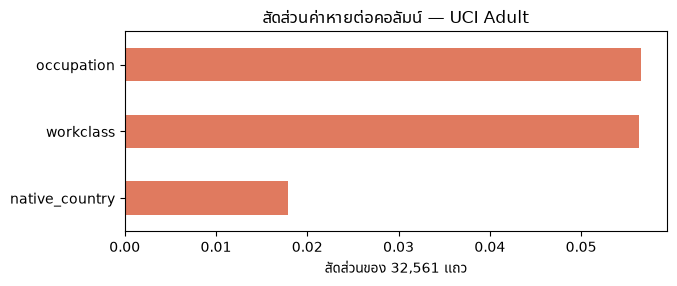

In [6]:
# ค่าหายอยู่แค่ 3 คอลัมน์: workclass (1,836), occupation (1,843),
# native_country (583) — จาก 32,561 แถว ~5-7% ดูภาพรวมด้วยกราฟ:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

miss = adult.isna().mean().loc[lambda s: s > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 2.6))
miss.plot.barh(ax=ax, color="#e07a5f")
ax.set_title("สัดส่วนค่าหายต่อคอลัมน์ — UCI Adult")
ax.set_xlabel("สัดส่วนของ 32,561 แถว")
plt.show()

### จัดการยังไง? — ไม่มีคำตอบเดียวที่ถูกเสมอ

ทางเลือกมีสองทางหลัก และ**การเลือกคือการตัดสินใจที่ต้องมีเหตุผล**:

In [7]:
# จัดการยังไง? — ไม่มีคำตอบเดียวที่ถูกเสมอ ทางเลือกมีสองทางหลัก
# และ "การเลือกคือการตัดสินใจที่ต้องมีเหตุผล":
# ทางที่ 1 — ตัดแถวที่มีค่าหายทิ้ง (เหลือเท่าไหร่?)
adult_drop = adult.dropna(subset=["workclass", "occupation"])
print(f"ตัดทิ้งแล้วเหลือ {len(adult_drop):,} จาก {len(adult):,} แถว "
      f"(เสีย {(1 - len(adult_drop) / len(adult)):.1%})")

# ทางที่ 2 — เติมด้วยค่าที่พบบ่อยสุด (mode) — ระวัง: สมมติฐานที่เราสร้างเอง!
adult_fill = adult.copy()
adult_fill["workclass"] = adult_fill["workclass"].fillna(
    adult_fill["workclass"].mode()[0])
print(f"เติมแล้ว workclass หายเหลือ "
      f"{adult_fill['workclass'].isna().sum()} ค่า")
# สังเกต: การเติม mode ทำให้กลุ่ม Private โตขึ้นเทียม ๆ —
# ถ้าคำถามผูกกับสัดส่วนกลุ่มอาชีพ อย่าเพิ่งเติม! กฎมือใหม่:
# ตัดทิ้งถ้าเสียไม่ถึง ~10%, ถ้าคิดไม่ตก ค้างไว้แล้วพูดถึง
# ข้อจำกัดในรายงาน


ตัดทิ้งแล้วเหลือ 30,718 จาก 32,561 แถว (เสีย 5.7%)
เติมแล้ว workclass หายเหลือ 0 ค่า


## ✏️ ลองเอง 2 — นับแถวที่ข้อมูลหาย

ใน `adult` ค่า `?` ถูกแปลงเป็น `NaN` ไปแล้ว — มีกี่แถวที่ `workclass`, `occupation` หรือ `native_country` หายไปอย่างน้อยหนึ่งคอลัมน์? ใช้เงื่อนไขแบบ boolean แล้วห่อด้วย `len` พิมพ์คำตอบแบบคั่นหลักพันด้วย comma

**คำใบ้:** สร้าง boolean Series จาก `adult[["workclass", "occupation", "native_country"]].isna().any(axis=1)` หรือรวมเงื่อนไขด้วย `|` แล้วนับด้วย `len`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์จำนวนแถวที่คอลัมน์ใดคอลัมน์หนึ่งในสามหายไป

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">2,399</pre>

</div>

## ✏️ ลองเอง 3 — เติมค่าว่างด้วยค่าคงที่ (fillna)

สร้างตัวแปร `occ_fill` โดยจำลองการเติมค่าว่างในคอลัมน์ `occupation` ของ `adult` ด้วยข้อความ `"Unknown"` จากนั้นพิมพ์จำนวนค่าว่างที่เหลืออยู่ในคอลัมน์นั้น

**คำใบ้:** ไวยากรณ์เติมค่าว่างคือ `series.fillna("ค่าที่ต้องการเติม")` แล้วนับค่าว่างที่เหลือด้วย `.isna().sum()`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# เติม "Unknown" ลงในช่องว่างของ occupation แล้วพิมพ์จำนวนค่าว่างที่เหลือ

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">0</pre>

</div>

## 3. ปัญหาที่ 2 — สะกดไม่ตรงและหน่วยปน (Coffee Quality)

ชุดที่สอง: รีวิวคุณภาพกาแฟ 1,311 แหล่งปลูก — ข้อมูลที่คนกรอกเอง **สกปรกแน่นกว่า** ข้อมูลที่เครื่องบันทึก:

In [8]:
coffee = pd.read_csv(
    data_root() / "coffee_quality" / "arabica_data_cleaned.csv")
print(coffee.shape)

# ค่าหายแบบ "แน่น" — หลายคอลัมน์, บางคอลัมน์แทบว่างทั้งต้น
miss_c = coffee.isna().mean().sort_values(ascending=False)
miss_c[miss_c > 0.1]

(1311, 44)


Lot.Number              0.794050
Farm.Name               0.271548
Mill                    0.236461
Color                   0.203661
Producer                0.175439
altitude_low_meters     0.173150
altitude_high_meters    0.173150
altitude_mean_meters    0.173150
Altitude                0.170099
Company                 0.159420
Variety                 0.153318
Processing.Method       0.115942
ICO.Number              0.112891
dtype: float64

### ปัญหาย่อย 2a — หน่วยวัดปนกันในคอลัมน์เดียว

คอลัมน์ `Altitude` (ความสูงจากระดับน้ำทะเล) ควรเป็นตัวเลข — แต่จริง ๆ แล้ว:

In [9]:
coffee["Altitude"].dropna().sample(12, random_state=42).tolist()

['1880 msnm',
 '1950',
 '1700',
 '1350-1500',
 '1650',
 '1000 m',
 '1000',
 '1550',
 '1100',
 '1300',
 '1750 msnm',
 '1200m']

In [10]:
# ปัญหาย่อย 2a — หน่วยวัดปนกันในคอลัมน์เดียว
# คนกรอกเขียนแบบตัวเอง: "1450 msnm", "1000 meters"
# บางรายให้มาเป็นช่วง "1200 - 1500" — ทางแก้: สกัดตัวเลขแรก
# ด้วย regular expression (ช่วงเราใช้ค่าต่ำ = สมมติฐาน
# ที่ต้องบอกต่อในรายงาน):
coffee["altitude_m"] = (
    coffee["Altitude"].astype("string")
    .str.extract(r"(\d+\.?\d*)").astype(float)
)
print("แปลงได้", coffee["altitude_m"].notna().sum(), "จาก",
      coffee["Altitude"].notna().sum(), "ค่าที่ไม่ว่าง")
coffee["altitude_m"].describe().round(0)

แปลงได้ 1085 จาก 1088 ค่าที่ไม่ว่าง


count      1085.0
mean       1752.0
std        5827.0
min           0.0
25%        1100.0
50%        1400.0
75%        1700.0
max      190164.0
Name: altitude_m, dtype: float64

## ✏️ ลองเอง 4 — สรุปค่าสถิติความสูงแหล่งปลูกกาแฟ

จากคอลัมน์ `coffee["altitude_m"]` ที่สกัดตัวเลขออกมาแล้ว จงหาค่ามัธยฐาน (`median`) และค่าเฉลี่ย (`mean`) ของความสูง แล้วพิมพ์ออกมาในรูปแบบ `median = <ค่า> | mean = <ค่า>` แบบปัดเศษจำนวนเต็ม

**คำใบ้:** ไวยากรณ์คำนวณคือ `coffee["altitude_m"].median()` และ `coffee["altitude_m"].mean()` แล้วจัดรูปแบบด้วย f-string

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์ median และ mean ของ coffee["altitude_m"] แบบปัดเศษจำนวนเต็ม

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">median = 1400 | mean = 1752</pre>

</div>

### ปัญหาย่อย 2b — ค่าเดียวกันสะกดหลายแบบ

ลองนับกลุ่มพันธุ์กาแฟ (`Variety`) — แล้วมองหา "พี่น้อง" ที่ควรรวมเป็นกลุ่มเดียว:

In [11]:
vc = coffee["Variety"].value_counts()
vc[vc < 15]  # กลุ่มเล็ก ๆ — ที่ซ่อนคนสะกดเพี้ยน

Variety
Pacas                    13
Gesha                    12
SL34                      8
Pacamara                  8
Peaberry                  5
Arusha                    5
Sumatra                   3
Mandheling                3
Ethiopian Yirgacheffe     2
Java                      2
Ruiru 11                  2
Blue Mountain             2
Sumatra Lintong           1
Ethiopian Heirlooms       1
Moka Peaberry             1
Sulawesi                  1
Marigojipe                1
Pache Comun               1
Name: count, dtype: int64

In [12]:
# ปัญหาย่อย 2b — ค่าเดียวกันสะกดหลายแบบ
# (V. Colombia กับ Colombia, Typica กับ Tico)
# รวมกลุ่มผ่าน dictionary mapping — list มาจากการเปิดดูข้อมูลจริง
# + ความรู้ในเนื้อหา ไม่ใช่เดา:
fix_variety = {
    "V. Colombia": "Colombia",
    "Tico": "Typica",
    "Bourbon Ponan": "Bourbon",
}
coffee["Variety"] = coffee["Variety"].replace(fix_variety)
print("กลุ่ม Variety: จาก", coffee["Variety"].nunique() + len(fix_variety),
      "เหลือ", coffee["Variety"].nunique(), "กลุ่ม")

กลุ่ม Variety: จาก 32 เหลือ 29 กลุ่ม


## ✏️ ลองเอง 5 — ตรวจการสะกดชื่อประเทศ

ตอนนี้พันธุ์กาแฟถูกจัดกลุ่มแล้ว — ตรวจอีกคอลัมน์หนึ่งที่คนกรอกเอง: `Country.of.Origin` มีประเทศไม่ซ้ำกี่ค่า? พิมพ์จำนวนนั้น แล้วพิมพ์ 3 อันดับแรกจาก `value_counts()`

**คำใบ้:** ใช้ `.nunique()` สำหรับจำนวนกลุ่ม และ `.value_counts().head(3)` สำหรับอันดับ — สังเกตด้วยว่ามีชื่อประเทศที่ใกล้เคียงกันแต่ไม่เหมือนกันหรือไม่

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์จำนวนประเทศไม่ซ้ำ แล้วพิมพ์ 3 อันดับแรกด้วย print(...)

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">36 ประเทศ
Country.of.Origin
Mexico       236
Colombia     183
Guatemala    181
Name: count, dtype: int64</pre>

</div>

## ✏️ ลองเอง 6 — ตรวจสอบวิธีการแปรรูปกาแฟ

ตรวจสอบคอลัมน์ `coffee["Processing.Method"]` ว่ามีรูปแบบการแปรรูปที่ไม่ซ้ำกี่แบบ และแสดง 4 อันดับแรกที่พบบ่อยที่สุดด้วย `value_counts()`

**คำใบ้:** ไวยากรณ์นับแบบไม่ซ้ำคือ `coffee["Processing.Method"].nunique()` และนับความถี่คือ `coffee["Processing.Method"].value_counts().head(4)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# พิมพ์จำนวนรูปแบบที่ไม่ซ้ำ และแสดง 4 อันดับแรกของ Processing.Method

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">5 รูปแบบ
Processing.Method
Washed / Wet                 812
Natural / Dry                251
Semi-washed / Semi-pulped     56
Other                         26
Name: count, dtype: int64</pre>

</div>

### ปัญหาย่อย 2c — แถวซ้ำซ้อน

รีวิวบางรายการถูก scrape ซ้ำมาหลายแถว ต่างกันแค่รหัสแถว — ตรวจโดยเทียบคอลัมน์เนื้อหา (ไม่เอาคอลัมน์ id):

In [13]:
# ปัญหาย่อย 2c — แถวซ้ำซ้อน: รีวิวเดียวกันถูก scrape ซ้ำหลายแถว
# ต่างกันแค่รหัสแถว — ตรวจโดยเทียบคอลัมน์เนื้อหา (ไม่เอา id):
content_cols = [c for c in coffee.columns
                if c not in ("Unnamed: 0", "altitude_m")]
dupes = coffee.duplicated(subset=content_cols, keep=False)
coffee.loc[dupes, ["Unnamed: 0", "Farm.Name", "Country.of.Origin",
                   "Total.Cup.Points"]]

,Unnamed: 0,Farm.Name,Country.of.Origin,Total.Cup.Points


In [14]:
# 3 แถวนี้คือรีวิวเดียวกัน เก็บซ้ำ 3 ครั้ง — ถ้าเอาไปเฉลี่ยคะแนน
# คาแฟแห่งนี้จะ "หนัก" 3 เท่าของคนอื่น แก้ด้วย drop_duplicates:
before = len(coffee)
coffee = coffee.drop_duplicates(subset=content_cols, keep="first")
print(f"ลบแถวซ้ำ {before - len(coffee)} แถว — เหลือ {len(coffee)}")

ลบแถวซ้ำ 0 แถว — เหลือ 1311


## ✏️ ลองเอง 7 — ตรวจสอบคู่ประเทศและฟาร์มที่ซ้ำซ้อน

ในการเก็บข้อมูลรีวิวกาแฟ ลองตรวจสอบว่าถ้าพิจารณาเฉพาะคู่คอลัมน์ `["Country.of.Origin", "Farm.Name"]` จะพบข้อมูลที่ซ้ำกันกี่แถว โดยใช้คำสั่ง `.duplicated()`

**คำใบ้:** ไวยากรณ์ตรวจสอบแถวซ้ำในบางคอลัมน์คือ `coffee.duplicated(subset=["Country.of.Origin", "Farm.Name"]).sum()`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# นับจำนวนแถวที่ซ้ำซ้อนในคอลัมน์ Country.of.Origin และ Farm.Name

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">พบแถวซ้ำ: 717 แถว</pre>

</div>

## 4. ปัญหาที่ 3 — วันที่แปลกและ Encoding (ไฟล์ไทย)

ชุดสุดท้าย: ข้อมูล PM2.5 จุดวัดใน กทม. ปี 2556 — ไฟล์จริงจากหน่วยงานรัฐไทย
ปัญหาแรกที่เจอทันที: **encoding** — ลองเปิดแบบปกติ:

In [15]:
try:
    pd.read_csv(
        data_root() / "pcd_pm25_legacy"
        / "aqpm2.5bangkokmetropolitanregion2556.csv")
except UnicodeDecodeError as e:
    print("พังตามคาด:", str(e)[:120], "...")

พังตามคาด: 'utf-8' codec can't decode byte 0xcb in position 10232: invalid continuation byte ...


In [16]:
# ไฟล์นี้ถูกเขียนด้วย TIS-620 — รหัสอักขระภาษาไทยก่อนยุค UTF-8
# (ไฟล์ไทยเก่าจากหน่วยงานราชการมักเป็นรหัสนี้)
legacy = pd.read_csv(
    data_root() / "pcd_pm25_legacy"
    / "aqpm2.5bangkokmetropolitanregion2556.csv",
    encoding="tis-620",   # มาตรฐานรหัสอักขระภาษาไทย
)
legacy.head(4)

,Date,54T,27T,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,1/1/2013,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1/2/2013,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1/3/2013,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1/4/2013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


อ่านออกแล้ว แต่สังเกต 4 อย่าง:

1. **หัวตารางแบบ pivot** — "คอลัมน์" หลัง `Date` คือรหัสจุดวัด (`54T`, `27T`, ...) ไม่ใช่ค่าที่วัด
   (ต้องแกะด้วย `melt`)
2. **มีคอลัมน์ `Unnamed: N` ว่าง ๆ ต่อท้าย** — เศษ comma จากการ export
3. **วันที่รูปแบบ `M/D/YYYY`** — ไม่ใช่มาตรฐานไทย
4. **แถวสุดท้ายเป็น "หมายเหตุ"** ไม่ใช่ข้อมูล — และค่าวัดจริงปีนี้ว่างเยอะ (จุดวัดอัตโนมัติยุคนั้นน้อย)

In [17]:
# ตัดแถวหมายเหตุท้ายตารางทิ้งก่อน — ไม่งั้น parse วันที่พัง
first_col = legacy.iloc[:, 0].astype("string")
data = legacy[first_col.str.match(r"\d", na=False)].copy()
print("แถวข้อมูล:", len(data), "| แถวที่ตัดทิ้ง:", len(legacy) - len(data))
data.iloc[:, :5]  # ดู 4 คอลัมน์วันที่แรก

แถวข้อมูล: 365 | แถวที่ตัดทิ้ง: 2


,Date,54T,27T,Unnamed: 3,Unnamed: 4
0,1/1/2013,43,NaN,NaN,NaN
1,1/2/2013,56,NaN,NaN,NaN
2,1/3/2013,59,NaN,NaN,NaN
3,1/4/2013,NaN,NaN,NaN,NaN
4,1/5/2013,NaN,NaN,NaN,NaN
...,...,...,...,...,...
360,12/27/2013,NaN,129.0,NaN,NaN
361,12/28/2013,NaN,130.0,NaN,NaN
362,12/29/2013,NaN,115.0,NaN,NaN
363,12/30/2013,NaN,108.0,NaN,NaN


In [18]:
# แกะจาก pivot เป็นตารางยาว (long format) แล้วแปลงวันที่
# errors="coerce" ทำให้วันที่แปลกกลายเป็น NaT แทนที่จะพัง:
long = data.melt(id_vars=data.columns[0],
                 var_name="date_raw", value_name="pm25")
long["date"] = pd.to_datetime(
    long["date_raw"], format="%m/%d/%Y", errors="coerce")
print("แปลงวันที่ไม่ได้:", long["date"].isna().sum(), "แถว")
long.dropna(subset=["date"]).head(3)

แปลงวันที่ไม่ได้: 5475 แถว


,Date,date_raw,pm25,date


## ✏️ ลองเอง 8 — ตรวจสอบช่วงวันที่ของข้อมูล PM2.5

จากตาราง `data` (ข้อมูล PM2.5 ที่ตัดแถวหมายเหตุทิ้งแล้ว) จงแปลงคอลัมน์ `data["Date"]` เป็น datetime ด้วย `pd.to_datetime()` แล้วพิมพ์วันที่เริ่มต้น (`min()`), วันที่สิ้นสุด (`max()`) และจำนวนวันทั้งหมด

**คำใบ้:** แปลงวันที่ด้วย `dates = pd.to_datetime(data["Date"], format="%m/%d/%Y")` แล้วหา `dates.min().strftime('%Y-%m-%d')`, `dates.max().strftime('%Y-%m-%d')` และ `len(dates)`

In [ ]:
# ลองเขียนโค้ดของคุณที่นี่
# แปลง data["Date"] เป็น datetime แล้วพิมพ์วันที่เริ่มต้น, สิ้นสุด และจำนวนวัน

<div style="background-color:#e8f1fb; border-left:4px solid #2b6cb0; padding:10px 14px; border-radius:4px; color:#123d6b;">

**ผลลัพธ์ที่คาดหวัง**

<pre style="margin:8px 0 0 0; white-space:pre-wrap; color:#123d6b;">ช่วงวันที่: 2013-01-01 ถึง 2013-12-31 (ทั้งหมด 365 วัน)</pre>

</div>

## 5. เช็คลิสต์ "ข้อมูลสะอาดพอแล้ว" + สรุป

ก่อนหยิบตารางไปวิเคราะห์/พล็อต — ไล่เช็ค 6 ข้อ:

- [ ] แถวหัวตารางเป็นชื่อคอลัมน์จริง (ไม่ใช่ข้อมูลแถวแรก)
- [ ] ค่าปลอม (`?`, `N/A`, `-999`) ถูกเปลี่ยนเป็น `NaN` และ**ตัดสินใจจัดการแล้ว** (ตัด/เติม + มีเหตุผล)
- [ ] คอลัมน์ตัวเลขเป็น dtype ตัวเลขจริง (ไม่ติดหน่วย/ข้อความปน)
- [ ] ค่าหมวดหมู่สะกดตรงกัน (เช็คด้วย `value_counts()`)
- [ ] แถวซ้ำถูกจัดการ (`duplicated()` + `drop_duplicates()`)
- [ ] วันที่เป็น `datetime` จริง (เช็ค `dt.year`, `dt.month` ใช้ได้)

**ทำไมเรื่องนี้ต้องมาก่อนทุกอย่าง:** ต่อจากนี้เราจะเอาข้อมูลสะอาดไปวาดกราฟ (M4) ก่อนเลิกวันนี้
แล้วพรุ่งนี้หาสถิติ (M5) และพยากรณ์ (M6) — สถิติที่คำนวณจากข้อมูลที่ยังมีแถวซ้ำ/ค่าปลอม จะนำไปสู่กราฟที่สวย
แต่**โกหก** การทำข้อมูลให้สะอาดจึงไม่ใช่งานเช็ค ๆ แต่คือครึ่งหนึ่งของการวิเคราะห์

**แล็บต่อ:** เปิด `exercise.ipynb` — ทำมือจริงทั้ง 4 ปัญหา ด้วยข้อมูลชุดเดียวกัน